In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = "images"
EXPRESSIONS = ["neutral", "smiling", "surprised"]
VALID_EXT = (".jpg", ".jpeg", ".png")
TARGET_SIZE = (256, 256)  # every image resized to the same dimensions

In [2]:
def find_image(member_dir, expression):
    """Return the path for an expression, accepting .jpg/.jpeg/.png."""
    for ext in VALID_EXT:
        path = os.path.join(member_dir, expression + ext)
        if os.path.exists(path):
            return path
    return None


def discover_members(image_dir=IMAGE_DIR):
    """Scan images/ and report which members have all 3 expressions."""
    members = {}
    for name in sorted(os.listdir(image_dir)):
        member_dir = os.path.join(image_dir, name)
        if not os.path.isdir(member_dir):
            continue
        paths = {exp: find_image(member_dir, exp) for exp in EXPRESSIONS}
        missing = [exp for exp, p in paths.items() if p is None]
        if missing:
            print(f"⚠ {name}: missing {missing}")
        else:
            print(f"✓ {name}: all 3 expressions found")
        members[name] = {exp: p for exp, p in paths.items() if p}
    return members


members = discover_members()
print(f"\nTotal members found: {len(members)}")

✓ Anglebert: all 3 expressions found
✓ Mukasa: all 3 expressions found
✓ Nina: all 3 expressions found

Total members found: 3


In [3]:
def load_image(path, size=TARGET_SIZE):
    """Load an image as RGB and resize it so all images share one shape."""
    image = cv2.imread(path)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return cv2.resize(image, size, interpolation=cv2.INTER_AREA)


images = {
    member: {exp: load_image(path) for exp, path in paths.items()}
    for member, paths in members.items()
}

for member, exps in images.items():
    for exp, img in exps.items():
        print(f"{member:12s} {exp:10s} shape={img.shape} dtype={img.dtype}")

Anglebert    neutral    shape=(256, 256, 3) dtype=uint8
Anglebert    smiling    shape=(256, 256, 3) dtype=uint8
Anglebert    surprised  shape=(256, 256, 3) dtype=uint8
Mukasa       neutral    shape=(256, 256, 3) dtype=uint8
Mukasa       smiling    shape=(256, 256, 3) dtype=uint8
Mukasa       surprised  shape=(256, 256, 3) dtype=uint8
Nina         neutral    shape=(256, 256, 3) dtype=uint8
Nina         smiling    shape=(256, 256, 3) dtype=uint8
Nina         surprised  shape=(256, 256, 3) dtype=uint8


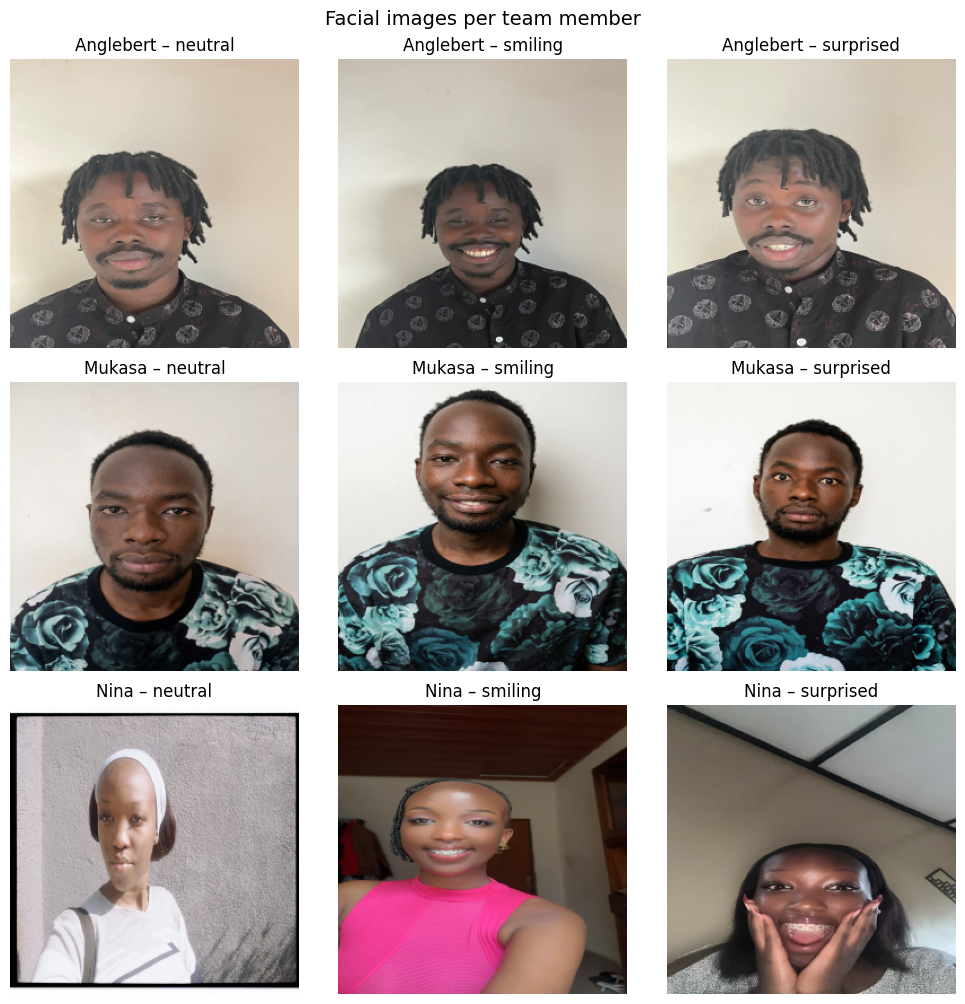

In [4]:
def display_member_grid(images):
    n = len(images)
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.4 * n), squeeze=False)
    for row, (member, exps) in enumerate(images.items()):
        for col, exp in enumerate(EXPRESSIONS):
            ax = axes[row][col]
            if exp in exps:
                ax.imshow(exps[exp])
            else:
                ax.text(0.5, 0.5, "missing", ha="center", va="center")
            ax.set_title(f"{member} – {exp}")
            ax.axis("off")
    plt.suptitle("Facial images per team member", fontsize=14)
    plt.tight_layout()
    plt.show()


display_member_grid(images)

In [5]:
AUG_DIR = "augmented_images"


def flip_horizontal(image):
    return cv2.flip(image, 1)


def rotate(image, angle=15):
    h, w = image.shape[:2]
    matrix = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    # BORDER_REFLECT avoids black corners after rotation
    return cv2.warpAffine(image, matrix, (w, h), borderMode=cv2.BORDER_REFLECT)


def to_grayscale(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    # Keep 3 channels so every image has the same shape for feature extraction
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)


def adjust_brightness(image, alpha=1.2, beta=30):
    """alpha = contrast multiplier, beta = brightness offset."""
    return cv2.convertScaleAbs(image, alpha=alpha, beta=beta)


AUGMENTATIONS = {
    "flipped": flip_horizontal,
    "rotated": rotate,
    "grayscale": to_grayscale,
    "bright": adjust_brightness,
}

In [6]:
def augment_all(images):
    """Return {member: {expression: {aug_name: image}}}, including the original."""
    augmented = {}
    for member, exps in images.items():
        member_dir = os.path.join(AUG_DIR, member)
        os.makedirs(member_dir, exist_ok=True)
        augmented[member] = {}

        for exp, img in exps.items():
            versions = {"original": img}
            for aug_name, fn in AUGMENTATIONS.items():
                versions[aug_name] = fn(img)

            for aug_name, aug_img in versions.items():
                if aug_name == "original":
                    continue
                out_path = os.path.join(member_dir, f"{exp}_{aug_name}.jpg")
                cv2.imwrite(out_path, cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR))

            augmented[member][exp] = versions
    return augmented


augmented = augment_all(images)

total = sum(len(v) for exps in augmented.values() for v in exps.values())
print(f"Total images (originals + augmented): {total}")
print(f"Saved augmented files: {sum(len(f) for _, _, f in os.walk(AUG_DIR))}")

Total images (originals + augmented): 45
Saved augmented files: 36


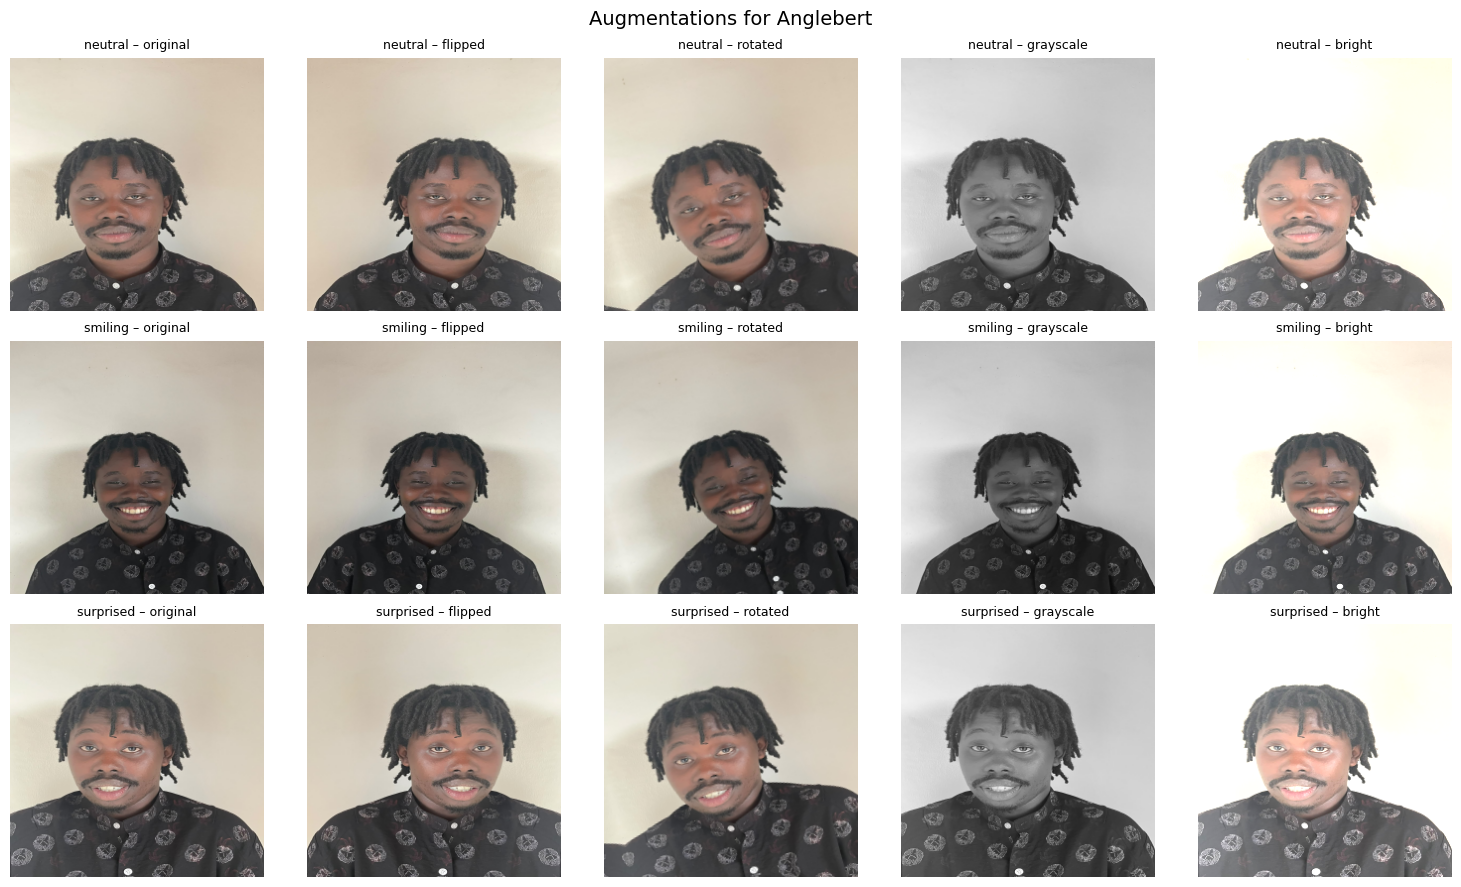

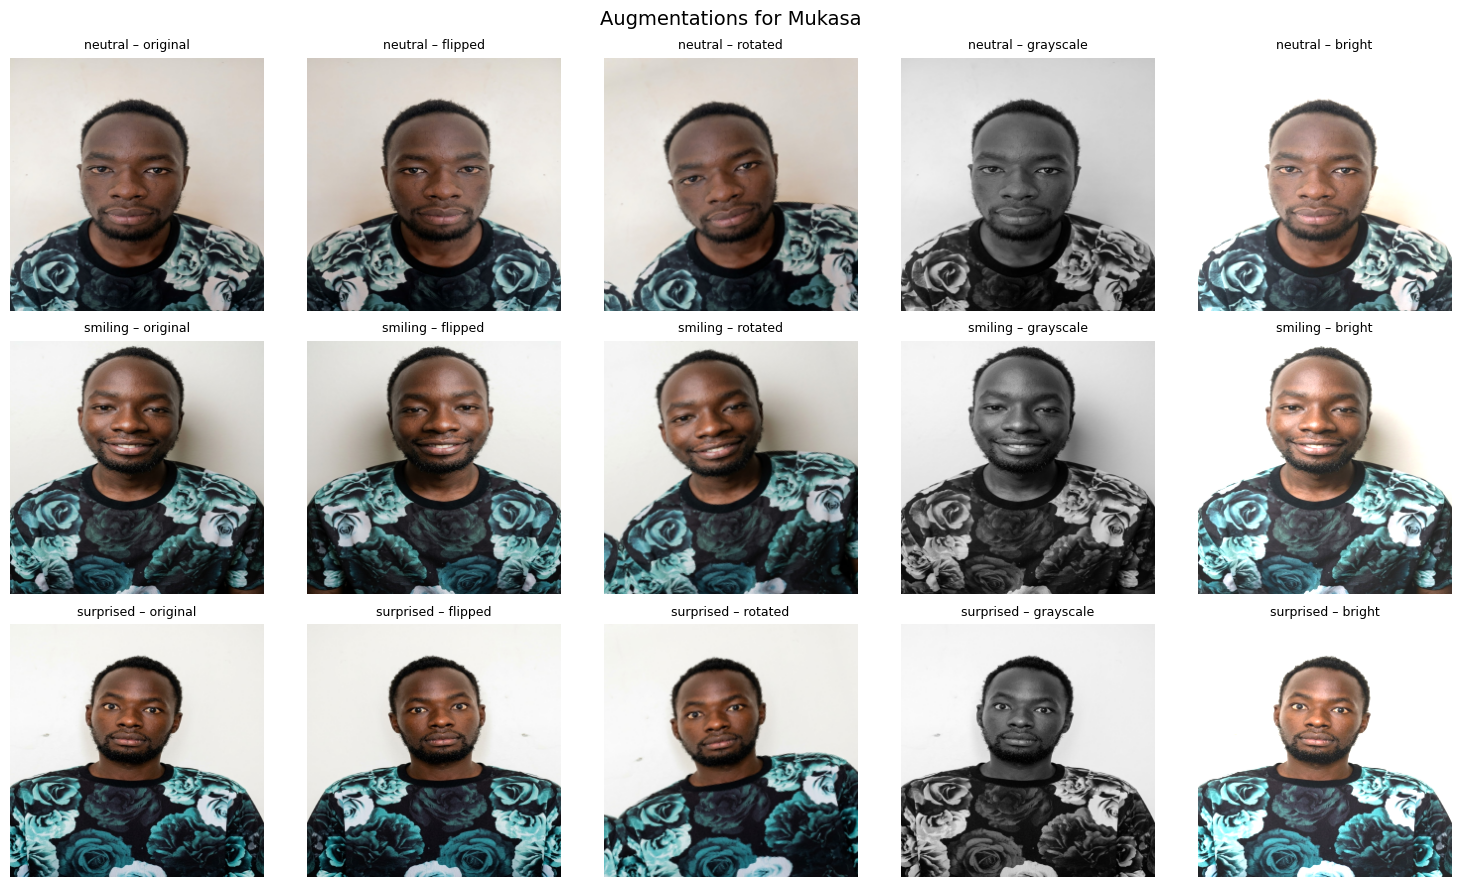

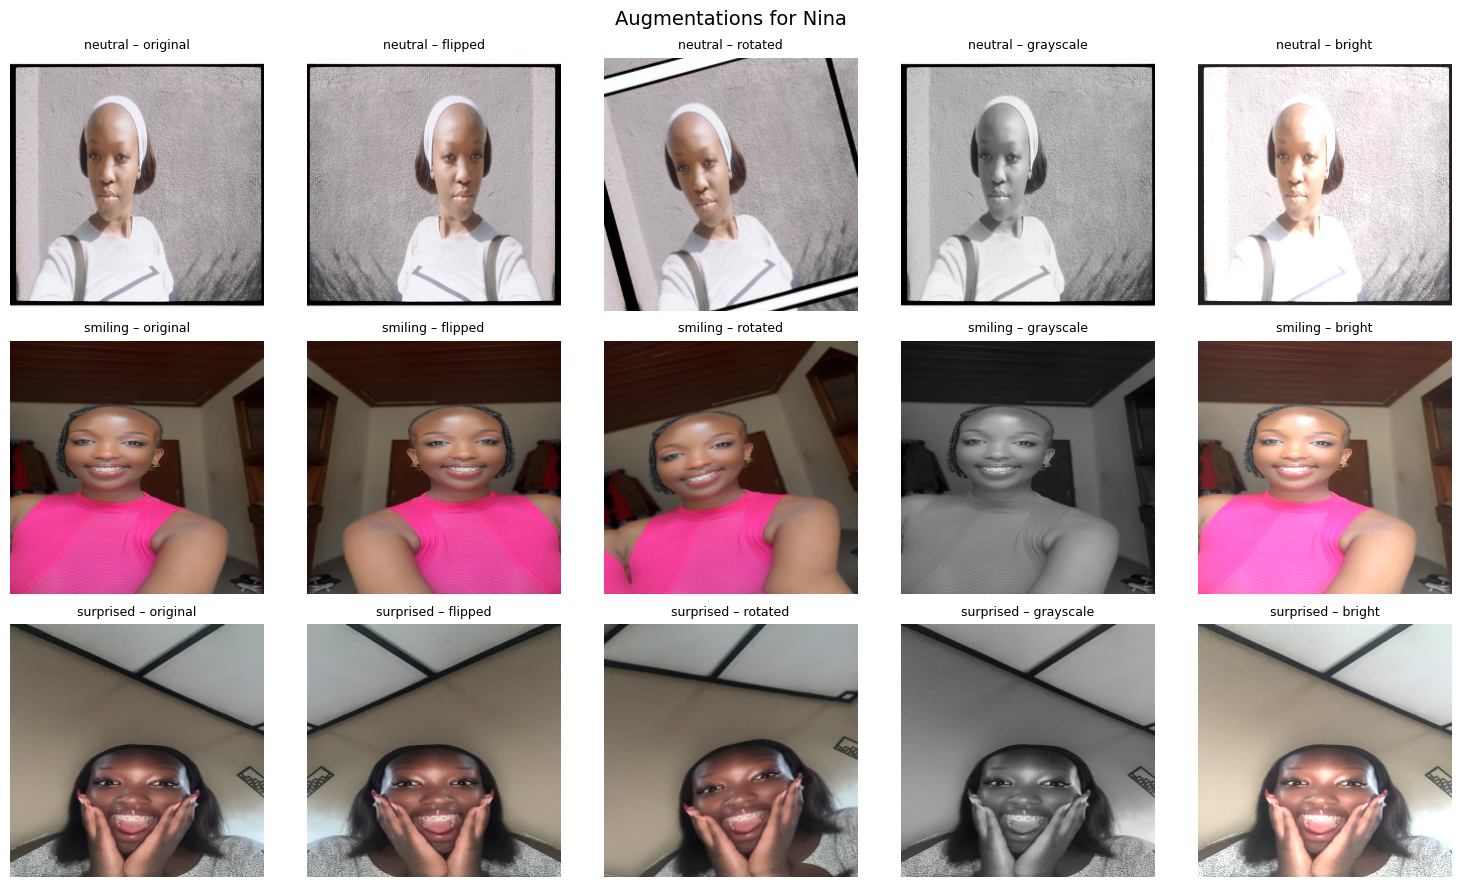

In [7]:
def display_augmentations(augmented, member):
    versions = ["original"] + list(AUGMENTATIONS.keys())
    fig, axes = plt.subplots(3, len(versions), figsize=(3 * len(versions), 9))
    for row, exp in enumerate(EXPRESSIONS):
        for col, aug_name in enumerate(versions):
            ax = axes[row][col]
            ax.imshow(augmented[member][exp][aug_name])
            ax.set_title(f"{exp} – {aug_name}", fontsize=9)
            ax.axis("off")
    plt.suptitle(f"Augmentations for {member}", fontsize=14)
    plt.tight_layout()
    plt.show()


for member in augmented:
    display_augmentations(augmented, member)